# Libs

In [1]:
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.metrics import average_precision_score, roc_auc_score

# Plot Style

In [2]:
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e5e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#52514e",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

COLOR_EXISTING = "#2a78d6"  # categorical slot 1 (blue)
COLOR_NEW = "#eb6834"  # categorical slot 2 (orange)
COLOR_AQUA = "#1baf7a"  # categorical slot 3
COLOR_YELLOW = "#eda100"  # categorical slot 4
COLOR_NEUTRAL = "#8a8a85"  # muted reference lines
SEQUENTIAL_BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab"]
CANDIDATE_COLORS = {
    "final_model": COLOR_EXISTING,
    "recency_rule": COLOR_NEW,
    "rfm_rule": COLOR_AQUA,
    "random": COLOR_NEUTRAL,
    "expected_loss": COLOR_YELLOW,
}

# Helpers

In [3]:
LOG_FEATURES = [
    "monetary_so_far", "avg_order_value_so_far", "tenure_days",
    "mean_gap_so_far", "recency_to_typical_gap", "activity_last_90d",
    "distinct_products_so_far", "cancel_count_so_far",
    "frequency_so_far",
]


def prepare_features(df, features):
    """Select feature columns, log1p-transforming the skewed ones.

    Reused unchanged from notebooks/04_modeling.ipynb (Section 6.1's
    note on feature scaling).

    Args:
        df: DataFrame containing `features`.
        features: List of feature column names to select.

    Returns:
        A new DataFrame with the same columns, skewed ones log1p-
        transformed.
    """
    X = df[features].copy()
    for col in features:
        if col in LOG_FEATURES:
            X[col] = np.log1p(X[col])
    return X

In [4]:
def precision_at_k(y_true, scores, k_frac):
    """Precision within the top k_frac of ranked scores."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    k = max(int(round(len(scores) * k_frac)), 1)
    top_idx = np.argsort(-scores)[:k]
    return y_true[top_idx].mean()


def lift_at_k(y_true, scores, k_frac):
    """Lift of the top k_frac segment over the overall base rate."""
    y_true = np.asarray(y_true)
    base_rate = y_true.mean()
    return precision_at_k(y_true, scores, k_frac) / base_rate


def gain_at_k(y_true, scores, k_frac):
    """Share of all positives captured within the top k_frac."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    k = max(int(round(len(scores) * k_frac)), 1)
    top_idx = np.argsort(-scores)[:k]
    return y_true[top_idx].sum() / y_true.sum()


def evaluate_ranking(y_true, scores, k_frac=0.10):
    """Pooled predictive + ranking metrics at one operating point."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    pct = int(k_frac * 100)
    return {
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        f"precision_at_{pct}": precision_at_k(y_true, scores, k_frac),
        f"lift_at_{pct}": lift_at_k(y_true, scores, k_frac),
        f"gain_at_{pct}": gain_at_k(y_true, scores, k_frac),
    }

In [5]:
def weekly_business_counts(df, score_col, revenue_col, k_frac):
    """Per-week targeting counts for the business-impact funnel.

    Section 7.3: for a given top-K%, each scoring week contributes
    customers targeted (n), true churners captured (tp), non-
    churners targeted (fp), revenue at risk among targeted churners,
    and that week's total churners (for Recall@K).

    Args:
        df: Rows with snapshot_date, churn, revenue_col and
            `score_col` columns.
        score_col: Name of the column holding the risk score.
        revenue_col: Name of the per-row revenue-at-risk column.
        k_frac: Top-K fraction targeted each week.

    Returns:
        A DataFrame with one row per scoring week: n, tp, fp,
        revenue_at_risk, positives.
    """
    rows = {}
    for week, week_df in df.groupby("snapshot_date"):
        n = max(int(round(len(week_df) * k_frac)), 1)
        top = week_df.sort_values(score_col, ascending=False).head(n)
        is_churn = top["churn"] == 1
        rows[week] = {
            "n": n,
            "tp": int(is_churn.sum()),
            "fp": int((~is_churn).sum()),
            "revenue_at_risk": top.loc[is_churn, revenue_col].sum(),
            "positives": int(week_df["churn"].sum()),
        }
    return pd.DataFrame(rows).T


def business_impact_scenario(counts, e, m, c_contact, c_inc, r):
    """Fold summed weekly counts into one business-impact scenario.

    Sections 7.3-7.6: period totals (summed across scoring weeks)
    feed the revenue/cost formulas; this is a scenario estimate
    under stated assumptions, not a measured causal impact (Online
    Retail II has no treatment/control data -- Section 7.10).

    Args:
        counts: Output of weekly_business_counts, summed with
            .sum() over the period.
        e: Assumed retention effectiveness (share of correctly
            targeted churners who are actually retained).
        m: Assumed gross margin on preserved revenue.
        c_contact: Assumed contact cost per targeted customer.
        c_inc: Assumed incentive cost per redemption.
        r: Assumed cannibalization rate (share of targeted non-
            churners who redeem anyway).

    Returns:
        A dict with n, tp, fp, recall_at_k, revenue_at_risk,
        revenue_preserved, gross_profit_preserved, contact_cost,
        incentive_cost, net_business_impact.
    """
    revenue_preserved = counts["revenue_at_risk"] * e
    gross_profit_preserved = revenue_preserved * m
    contact_cost = counts["n"] * c_contact
    incentive_cost = (counts["tp"] * e + counts["fp"] * r) * c_inc
    net_impact = gross_profit_preserved - contact_cost - incentive_cost
    return {
        "n": counts["n"],
        "tp": counts["tp"],
        "fp": counts["fp"],
        "recall_at_k": counts["tp"] / counts["positives"],
        "revenue_at_risk": counts["revenue_at_risk"],
        "revenue_preserved": revenue_preserved,
        "gross_profit_preserved": gross_profit_preserved,
        "contact_cost": contact_cost,
        "incentive_cost": incentive_cost,
        "net_business_impact": net_impact,
    }

In [6]:
def expected_orders_in_h(df, horizon_days, max_orders):
    """Purchases a customer would make within the horizon if retained.

    Section 7.2: horizon_days / mean_gap_so_far, clipped to
    [1, max_orders]. Customers with a single purchase so far have no
    gap yet and count as one order.

    Args:
        df: Rows with a mean_gap_so_far column.
        horizon_days: Prediction horizon H in days.
        max_orders: Upper clip (e.g. one purchase per week).

    Returns:
        A Series of expected orders aligned with df.
    """
    orders = horizon_days / df["mean_gap_so_far"]
    return orders.clip(lower=1, upper=max_orders).fillna(1.0)


def simulate_targeting(df, score_col, k_frac, counting,
                       suppression_weeks=13):
    """Rows targeted over the test period under one counting scheme.

    Section 7.7. Every week the budget is N_K = round(K x active
    customers that week).
    - "weekly": top N_K of all active customers, every week (the
      Sections 7.3-7.6 reference; a customer can be counted in many
      consecutive weeks).
    - "unique": same weekly selection, but each customer counts only
      the first week they are targeted.
    - "suppressed": top N_K among customers not contacted in the
      previous `suppression_weeks` weeks (Section 8.5's suppression
      rule), so the budget moves on to other customers.

    Args:
        df: Rows with snapshot_date, customer_id, churn and
            `score_col` columns.
        score_col: Name of the column holding the ranking score.
        k_frac: Top-K fraction targeted each week.
        counting: "weekly", "unique" or "suppressed".
        suppression_weeks: Weeks a contacted customer is excluded
            ("suppressed" only).

    Returns:
        A DataFrame of the targeted rows, in week order.
    """
    selected = []
    suppressed_until = {}
    weeks = sorted(df["snapshot_date"].unique())
    for week_idx, week in enumerate(weeks):
        week_df = df[df["snapshot_date"] == week]
        n = max(int(round(len(week_df) * k_frac)), 1)
        if counting == "suppressed":
            eligible = week_df[
                week_df["customer_id"].map(suppressed_until).fillna(-1)
                <= week_idx
            ]
        else:
            eligible = week_df
        top = eligible.sort_values(score_col, ascending=False).head(n)
        if counting == "suppressed":
            for customer in top["customer_id"]:
                suppressed_until[customer] = week_idx + suppression_weeks
        selected.append(top)
    targeted = pd.concat(selected)
    if counting == "unique":
        targeted = targeted.drop_duplicates("customer_id", keep="first")
    return targeted


def targeting_counts(targeted, revenue_col, positives):
    """Period totals of a targeted set, in business_impact_scenario form.

    Args:
        targeted: Output of simulate_targeting.
        revenue_col: Per-row revenue-at-risk column to sum over the
            targeted churners.
        positives: Total churn rows in the period (for Recall@K).

    Returns:
        A dict with n, tp, fp, revenue_at_risk, positives.
    """
    is_churn = targeted["churn"] == 1
    return {
        "n": len(targeted),
        "tp": int(is_churn.sum()),
        "fp": int((~is_churn).sum()),
        "revenue_at_risk": targeted.loc[is_churn, revenue_col].sum(),
        "positives": positives,
    }

# Load

In [7]:
modeling_dataset = pd.read_parquet(
    "../data/processed/modeling_dataset_h90.parquet"
)
modeling_dataset.shape

(208764, 25)

**Chosen parameters and assumptions.** Inherited from Chapters 4-6:
$H=90$ days, $R_{\max}=136$ days, and the final model of Section 6.2
(Logistic Regression, Extended feature set, $C=0.01$, every active
row weighted $1/n_i$ per customer, with its calibration offset),
loaded from `models/churn_model_h90.joblib` as saved by
`notebooks/04_modeling.ipynb`. Business assumptions for this chapter,
clearly stated so they can be varied: contact cost
$c_{\text{contact}}=\pounds0.50$/customer, gross margin $m=35\%$,
incentive cost $c_{\text{inc}}=\pounds5.00$/redemption,
cannibalization $r=20\%$, retention effectiveness
$e \in \{30\%, 40\%, 50\%\}$. Measurement parameters (Sections 7.2
and 7.7): at most 13 expected orders within $H$ (one per week), and
a 13-week ($\approx H$) suppression period after a customer is
contacted. The scoring output (Section 7.11) uses the 10
fixed-cut-off risk bands saved with the model (Section 6.3).

In [8]:
H = 90

RFM_FEATURES = ["recency_days", "frequency_so_far", "monetary_so_far"]

C_CONTACT = 0.50
MARGIN = 0.35
C_INCENTIVE = 5.00
CANNIBALIZATION = 0.20
EFFECTIVENESS_SCENARIOS = [0.30, 0.40, 0.50]
K_FRACS = [0.10, 0.20, 0.30, 0.40, 0.50]

N_RISK_BANDS = 10
MAX_ORDERS_IN_H = 13  # one purchase per week
SUPPRESSION_WEEKS = 13  # ~ H: one contact per churn window
REVENUE_MEASURES = {
    "aov": "rar_aov",
    "value_v": "rar_v",
    "value_v_x_orders": "rar_v_orders",
}
COUNTING_SCHEMES = ["weekly", "unique", "suppressed"]

## 7.1 Evaluation Framework

Estimate the business value of targeting with the final model of
Chapter 6 on the unseen test period. All evaluation uses the Scoring
Population (every row in `split=="test"`). Besides the final model
and the three baselines (recency rule, RFM rule, random), the
**Expected Loss** ranking -- calibrated churn probability $\times$
revenue at risk ($V \times$ expected orders, Section 7.2) -- uses the
same fitted model with a value-aware ranking key. The historical
data contain no real campaigns, so suppression is not part of the
data; Section 7.7 simulates it as one of three ways to count a
weekly campaign.

In [9]:
model_path = f"../models/churn_model_h{H}.joblib"
base_artifact = joblib.load(model_path)
imputer = base_artifact["imputer"]
scaler = base_artifact["scaler"]
final_model = base_artifact["model"]
FINAL_FEATURES = base_artifact["features"]
CALIBRATION_OFFSET = base_artifact["calibration_offset"]
MODEL_VERSION = base_artifact["model_version"]
assert base_artifact["log_features"] == LOG_FEATURES
risk_band_edges = base_artifact["risk_band_edges"]
assert len(risk_band_edges) == N_RISK_BANDS + 1

train_df = modeling_dataset[modeling_dataset["split"] == "train"]
val_df = modeling_dataset[modeling_dataset["split"] == "validation"]
test_df = modeling_dataset[modeling_dataset["split"] == "test"].copy()

X_test = scaler.transform(
    imputer.transform(prepare_features(test_df, FINAL_FEATURES))
)
test_df["score_final_model"] = final_model.predict_proba(X_test)[:, 1]
test_df["score_final_model_calibrated"] = expit(
    final_model.decision_function(X_test) - CALIBRATION_OFFSET
)
print(f"Loaded {MODEL_VERSION} ({len(FINAL_FEATURES)} features, "
      f"logit offset {CALIBRATION_OFFSET:.3f})")
print(f"Test rows: {len(test_df):,} across "
      f"{test_df['snapshot_date'].nunique()} weeks")

Loaded lr_extended_c0.01_weighted_cal_h90 (8 features, logit offset 0.259)
Test rows: 24,252 across 10 weeks


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

In [10]:
rng = np.random.default_rng(0)
test_df["score_random"] = rng.uniform(size=len(test_df))
test_df["score_recency_rule"] = test_df["recency_days"]

rfm_train_mean = train_df[RFM_FEATURES].mean()
rfm_train_std = train_df[RFM_FEATURES].std()
rfm_z = (test_df[RFM_FEATURES] - rfm_train_mean) / rfm_train_std
test_df["score_rfm_rule"] = (
    rfm_z["recency_days"] - rfm_z["frequency_so_far"]
    - rfm_z["monetary_so_far"]
)

test_df["rar_aov"] = test_df["avg_order_value_so_far"]
test_df["rar_v"] = test_df["value_v"]
test_df["expected_orders_h"] = expected_orders_in_h(
    test_df, H, MAX_ORDERS_IN_H
)
test_df["rar_v_orders"] = test_df["rar_v"] * test_df["expected_orders_h"]
test_df["score_expected_loss"] = (
    test_df["score_final_model_calibrated"] * test_df["rar_v_orders"]
)

CANDIDATES = {
    "final_model": "score_final_model",
    "expected_loss": "score_expected_loss",
    "recency_rule": "score_recency_rule",
    "rfm_rule": "score_rfm_rule",
    "random": "score_random",
}

for col in test_df["segment"].unique():
    share = (test_df["segment"] == col).mean()
    print(f"segment={col}: {share:.1%} of test rows")

segment=repeat: 86.7% of test rows
segment=one-time: 13.3% of test rows


## 7.2 Customer Revenue at Risk

Three measures of what a churner's departure would cost, all using
history up to the snapshot date only (estimates of exposure, not
observed lost revenue):

- `rar_aov` -- one future purchase at the customer's raw average
  order value (`avg_order_value_so_far`); the reference measure of
  earlier versions.
- `rar_v` -- one purchase at the capped value $V$ (`value_v`,
  Section 5.5), so a handful of wholesale-sized accounts cannot
  dominate.
- `rar_v_orders` -- $V \times$ expected orders within $H$
  ($H / \text{mean gap}$, clipped to $[1, 13]$), so losing a
  frequent buyer costs more than losing an occasional one.

In [11]:
test_df[["rar_aov", "rar_v", "expected_orders_h", "rar_v_orders"]].describe().round(2)

,rar_aov,rar_v,expected_orders_h,rar_v_orders
count,24252.00,24252.00,24252.00,24252.00
mean,395.70,373.69,2.07,832.85
std,561.61,291.27,2.10,1633.57
min,2.90,2.90,1.00,2.90
25%,197.75,197.75,1.00,258.23
50%,303.58,303.58,1.20,448.88
75%,438.93,438.93,2.20,844.24
max,14844.77,1956.84,13.00,25438.92


## 7.3 Business Impact Scenario

For each candidate and each target share $K$, sum weekly targeting
counts (customers targeted $N_K$, true churners captured $TP_K$,
non-churners targeted $FP_K$, revenue at risk among targeted
churners) across the 10 test weeks. Sections 7.3-7.6 keep the
reference measurement of earlier versions -- weekly counting,
`rar_aov` -- so the funnel stays comparable; Section 7.7 varies
both.

In [12]:
weekly_counts = {
    (name, k): weekly_business_counts(
        test_df, col, "rar_aov", k
    )
    for name, col in CANDIDATES.items()
    for k in K_FRACS
}
period_counts = {
    key: counts.sum() for key, counts in weekly_counts.items()
}

business_scenario_10pct = pd.DataFrame({
    name: period_counts[(name, 0.10)] for name in CANDIDATES
}).T
business_scenario_10pct.round(2)

,n,tp,fp,revenue_at_risk,positives
final_model,2427.0,1831.0,596.0,406981.23,9714.0
expected_loss,2427.0,1132.0,1295.0,1165360.89,9714.0
recency_rule,2427.0,1521.0,906.0,538397.09,9714.0
rfm_rule,2427.0,1732.0,695.0,499916.48,9714.0
random,2427.0,986.0,1441.0,330372.57,9714.0


## 7.4 Retention Effectiveness Assumption

Retention success is an assumption: Conservative $e=30\%$, Base
$e=40\%$, Optimistic $e=50\%$.
\[
\text{RevenuePreserved} = \text{RevenueAtRisk(targeted churners)}
\times e
\]

In [13]:
revenue_preserved_10pct = pd.DataFrame({
    f"e={e:.0%}": {
        name: period_counts[(name, 0.10)]["revenue_at_risk"] * e
        for name in CANDIDATES
    }
    for e in EFFECTIVENESS_SCENARIOS
})
revenue_preserved_10pct.round(2)

,e=30%,e=40%,e=50%
final_model,122094.37,162792.49,203490.62
expected_loss,349608.27,466144.36,582680.45
recency_rule,161519.13,215358.84,269198.55
rfm_rule,149974.94,199966.59,249958.24
random,99111.77,132149.03,165186.28


## 7.5 Marketing Cost and the Value of the Model

If contact cost per customer is constant, targeting $K\%$ instead
of everyone reduces reach cost by $(1-K)$ -- this saving comes from
\textbf{targeting itself}, identical for every candidate at the
same $K$ (all target the same $N_K$). The model's own contribution
is measured by comparing, at the same $K=10\%$, the churners
captured and revenue preserved across candidates (Base scenario,
$e=40\%$).

In [14]:
cost_comparison = pd.DataFrame({
    name: {
        "customers_targeted": period_counts[(name, 0.10)]["n"],
        "churners_captured": period_counts[(name, 0.10)]["tp"],
        "revenue_preserved_base": (
            period_counts[(name, 0.10)]["revenue_at_risk"] * 0.40
        ),
        "contact_cost": (
            period_counts[(name, 0.10)]["n"] * C_CONTACT
        ),
    }
    for name in CANDIDATES
}).T
cost_comparison.round(2)

,customers_targeted,churners_captured,revenue_preserved_base,contact_cost
final_model,2427.0,1831.0,162792.49,1213.5
expected_loss,2427.0,1132.0,466144.36,1213.5
recency_rule,2427.0,1521.0,215358.84,1213.5
rfm_rule,2427.0,1732.0,199966.59,1213.5
random,2427.0,986.0,132149.03,1213.5


## 7.6 Net Business Impact

\begin{align*}
\text{GrossProfitPreserved} &= \text{RevenuePreserved} \times m \\
\text{ContactCost} &= N_K \times c_{\text{contact}} \\
\text{IncentiveCost} &= (TP_K \times e + FP_K \times r)
    \times c_{\text{inc}} \\
\text{NetBusinessImpact} &= \text{GrossProfitPreserved}
    - \text{ContactCost} - \text{IncentiveCost}
\end{align*}

In [15]:
net_impact_10pct_base = pd.DataFrame({
    name: business_impact_scenario(
        period_counts[(name, 0.10)], e=0.40, m=MARGIN,
        c_contact=C_CONTACT, c_inc=C_INCENTIVE, r=CANNIBALIZATION,
    )
    for name in CANDIDATES
}).T
net_impact_10pct_base.round(2)

,n,tp,fp,recall_at_k,revenue_at_risk,revenue_preserved,gross_profit_preserved,contact_cost,incentive_cost,net_business_impact
final_model,2427.0,1831.0,596.0,0.19,406981.23,162792.49,56977.37,1213.5,4258.0,51505.87
expected_loss,2427.0,1132.0,1295.0,0.12,1165360.89,466144.36,163150.52,1213.5,3559.0,158378.02
recency_rule,2427.0,1521.0,906.0,0.16,538397.09,215358.84,75375.59,1213.5,3948.0,70214.09
rfm_rule,2427.0,1732.0,695.0,0.18,499916.48,199966.59,69988.31,1213.5,4159.0,64615.81
random,2427.0,986.0,1441.0,0.10,330372.57,132149.03,46252.16,1213.5,3413.0,41625.66


## 7.7 Measurement Sensitivity: Value and Counting

The same candidates at $K=10\%$, $e=40\%$, under every combination
of the three revenue measures (Section 7.2) and three ways to count
a weekly campaign (`simulate_targeting`): **weekly** (reference --
a customer can be counted in many consecutive weeks), **unique**
(each customer counted once, at their first targeting) and
**suppressed** (a contacted customer is excluded for 13 weeks, so
the weekly budget moves on to other customers). `tp_customers` is
the number of distinct churners reached.

In [16]:
positives = int(test_df["churn"].sum())
sensitivity = {}
targeted_sets = {}
for counting in COUNTING_SCHEMES:
    rows = {}
    for name, col in CANDIDATES.items():
        targeted = simulate_targeting(
            test_df, col, 0.10, counting, SUPPRESSION_WEEKS
        )
        targeted_sets[(counting, name)] = targeted
        is_churn = targeted["churn"] == 1
        row = {
            "targeted": len(targeted),
            "tp": int(is_churn.sum()),
            "tp_customers": targeted.loc[is_churn, "customer_id"].nunique(),
        }
        for measure, rev_col in REVENUE_MEASURES.items():
            impact = business_impact_scenario(
                targeting_counts(targeted, rev_col, positives),
                e=0.40, m=MARGIN, c_contact=C_CONTACT,
                c_inc=C_INCENTIVE, r=CANNIBALIZATION,
            )
            row[f"net_{measure}"] = impact["net_business_impact"]
        rows[name] = row
    sensitivity[counting] = pd.DataFrame(rows).T

reference = sensitivity["weekly"]["net_aov"]
assert np.allclose(
    reference, net_impact_10pct_base["net_business_impact"]
)
for name in CANDIDATES:
    weeks = targeted_sets[("suppressed", name)].groupby("customer_id")[
        "snapshot_date"
    ].apply(lambda d: d.sort_values().diff().dt.days.min())
    assert (weeks.dropna() >= SUPPRESSION_WEEKS * 7).all()

pd.concat(sensitivity, names=["counting"]).round(0)

targeted      tp  tp_customers   net_aov  \
counting                                                             
weekly     final_model      2427.0  1831.0         425.0   51506.0   
           expected_loss    2427.0  1132.0         214.0  158378.0   
           recency_rule     2427.0  1521.0         542.0   70214.0   
           rfm_rule         2427.0  1732.0         531.0   64616.0   
           random           2427.0   986.0         719.0   41626.0   
unique     final_model       577.0   425.0         425.0   13679.0   
           expected_loss     431.0   199.0         199.0   24192.0   
           recency_rule      899.0   542.0         542.0   26072.0   
           rfm_rule          771.0   531.0         531.0   20134.0   
           random           1635.0   679.0         679.0   28731.0   
suppressed final_model      2427.0  1212.0        1212.0   54830.0   
           expected_loss    2427.0  1000.0        1000.0   54513.0   
           recency_rule     2427.0  1152.0        1152.0   52865.0   
           rfm_rule         2427.0  1220.0        1220.0   51350.0   
           random           2427.0   986.0         986.0   47364.0   

                          net_value_v  net_value_v_x_orders  
counting                                                     
weekly     final_model        51506.0               64698.0  
           expected_loss     112113.0              270653.0  
           recency_rule       63767.0               94395.0  
           rfm_rule           64616.0               84222.0  
           random             41329.0               72988.0  
unique     final_model        13679.0               17249.0  
           expected_loss      19090.0               44647.0  
           recency_rule       23234.0               33790.0  
           rfm_rule           20134.0               25920.0  
           random             28625.0               47586.0  
suppressed final_model        49787.0               77305.0  
           expected_loss      49411.0               81337.0  
           recency_rule       48144.0               75114.0  
           rfm_rule           49700.0               70273.0  
           random             42321.0               71258.0

## 7.8 Scenario Analysis

Net impact across weekly target shares under **suppressed counting**
(the budget-fair, operationally realistic scheme of Section 7.7),
for all three revenue measures, with $m$, $c_{\text{contact}}$,
$c_{\text{inc}}$ and $r$ held at the assumptions above and $e=40\%$.
Because a contacted customer is excluded for 13 weeks -- longer
than the 10-week test period -- weekly shares add up: at $K=10\%$
over 80% of all test customers are contacted at least once, and
every rule ends up reaching nearly the same customers, only in a
different order. Smaller weekly shares ($K = 1$--$5\%$) are where the
choice of ranking actually matters. The last column compares each
candidate to the recency rule under `rar_v_orders`.

In [17]:
SUPPRESSED_K_FRACS = [0.01, 0.02, 0.05, 0.10]
test_customers = test_df["customer_id"].nunique()

scenario_rows = []
for k in SUPPRESSED_K_FRACS:
    impacts = {}
    for name, col in CANDIDATES.items():
        targeted = simulate_targeting(
            test_df, col, k, "suppressed", SUPPRESSION_WEEKS
        )
        row = {
            "targeted": len(targeted),
            "customer_share": targeted["customer_id"].nunique()
            / test_customers,
            "tp": int((targeted["churn"] == 1).sum()),
        }
        for measure, rev_col in REVENUE_MEASURES.items():
            row[f"net_{measure}"] = business_impact_scenario(
                targeting_counts(targeted, rev_col, positives),
                e=0.40, m=MARGIN, c_contact=C_CONTACT,
                c_inc=C_INCENTIVE, r=CANNIBALIZATION,
            )["net_business_impact"]
        impacts[name] = row
    for name, row in impacts.items():
        scenario_rows.append({
            "K": f"{k:.0%}",
            "candidate": name,
            **row,
            "net_vs_recency": (
                row["net_value_v_x_orders"]
                - impacts["recency_rule"]["net_value_v_x_orders"]
            ),
        })

scenario_analysis = pd.DataFrame(scenario_rows).set_index(["K", "candidate"])
scenario_analysis.round(2)

targeted  customer_share    tp   net_aov  net_value_v  \
K   candidate                                                              
1%  final_model         241            0.08   185   3926.05      3926.05   
    expected_loss       241            0.08   113  17660.08     12558.32   
    recency_rule        241            0.08   166   6157.07      6157.07   
    rfm_rule            241            0.08   188   6501.21      6501.21   
    random              241            0.08   100   4881.74      4690.31   
2%  final_model         485            0.17   363  10776.06     10776.06   
    expected_loss       485            0.17   225  25704.10     20574.17   
    recency_rule        485            0.17   315  15057.18     13252.87   
    rfm_rule            485            0.17   362  13580.88     13580.88   
    random              485            0.17   189   7964.13      7964.13   
5%  final_model        1212            0.42   766  28865.56     27831.75   
    expected_loss      1212            0.42   517  40594.29     35492.53   
    recency_rule       1212            0.42   688  31174.94     28277.90   
    rfm_rule           1212            0.42   742  29214.39     28180.57   
    random             1212            0.42   496  21452.27     21347.09   
10% final_model        2427            0.83  1212  54830.10     49787.26   
    expected_loss      2427            0.83  1000  54512.66     49410.89   
    recency_rule       2427            0.83  1152  52865.25     48143.70   
    rfm_rule           2427            0.83  1220  51349.95     49700.22   
    random             2427            0.83   986  47363.55     42320.70   

                   net_value_v_x_orders  net_vs_recency  
K   candidate                                            
1%  final_model                 4899.03        -4535.80  
    expected_loss              35257.91        25823.09  
    recency_rule                9434.83            0.00  
    rfm_rule                    6969.35        -2465.48  
    random                      7462.43        -1972.40  
2%  final_model                12782.39        -7337.45  
    expected_loss              46366.49        26246.65  
    recency_rule               20119.84            0.00  
    rfm_rule                   17963.34        -2156.50  
    random                     15739.58        -4380.26  
5%  final_model                37030.67        -4164.17  
    expected_loss              65353.74        24158.90  
    recency_rule               41194.84            0.00  
    rfm_rule                   38050.84        -3144.00  
    random                     38304.88        -2889.96  
10% final_model                77304.52         2190.83  
    expected_loss              81337.22         6223.53  
    recency_rule               75113.69            0.00  
    rfm_rule                   70272.84        -4840.86  
    random                     71258.45        -3855.25

## 7.9 Model Comparison

Combine detection and business-impact metrics for all five
candidates: AUC (Section 6.3) and net impact under both the
reference measurement (weekly counting, `rar_aov`, $K=10\%$) and the
realistic one (suppressed counting, `rar_v_orders`, $K=5\%$ -- below
the saturation described in Section 7.8). No single "best" model
emerges from detection metrics alone -- business-impact performance
matters more for this targeting use case.

In [18]:
model_comparison_rows = {}
for name, col in CANDIDATES.items():
    impact = business_impact_scenario(
        period_counts[(name, 0.10)], e=0.40, m=MARGIN,
        c_contact=C_CONTACT, c_inc=C_INCENTIVE, r=CANNIBALIZATION,
    )
    model_comparison_rows[name] = {
        "auc": roc_auc_score(test_df["churn"], test_df[col]),
        "net_impact_reference": impact["net_business_impact"],
        "net_impact_suppressed_5pct": scenario_analysis.loc[
            ("5%", name), "net_value_v_x_orders"
        ],
    }

model_comparison = pd.DataFrame(model_comparison_rows).T
model_comparison.round(3)

,auc,net_impact_reference,net_impact_suppressed_5pct
final_model,0.759,51505.873,37030.675
expected_loss,0.533,158378.025,65353.741
recency_rule,0.638,70214.093,41194.841
rfm_rule,0.728,64615.807,38050.841
random,0.506,41625.659,38304.880


## 7.10 Error Analysis and Limitations

Targeting the top 10% by the final model's score (pooled across the
test period), investigate false positives (targeted, did not churn)
and false negatives (missed, did churn) by segment, country, and
wholesale-like status, plus performance by week (seasonal effects).
`country` is not a modeling feature (Section 5.5) and is rejoined
from the raw transaction table for this diagnostic only.

In [19]:
df_retail = pd.read_parquet("../data/raw/online_retail_II.parquet")
customer_country = (
    df_retail.rename(columns={"Customer ID": "customer_id"})
    .dropna(subset=["customer_id"])
    .groupby("customer_id")["Country"]
    .agg(lambda s: s.value_counts().idxmax())
)
test_df["country"] = test_df["customer_id"].map(customer_country)
test_df["is_uk"] = np.where(
    test_df["country"] == "United Kingdom", "UK", "non-UK"
)

revenue_p99 = train_df["monetary_so_far"].quantile(0.99)
test_df["wholesale_like"] = np.where(
    test_df["monetary_so_far"] >= revenue_p99, "wholesale-like", "retail"
)

n_top = max(int(round(len(test_df) * 0.10)), 1)
top_mask = test_df["score_final_model"].rank(
    ascending=False, method="first"
) <= n_top
test_df["targeted"] = top_mask
test_df["error_type"] = np.select(
    [
        top_mask & (test_df["churn"] == 1),
        top_mask & (test_df["churn"] == 0),
        (~top_mask) & (test_df["churn"] == 1),
    ],
    ["true_positive", "false_positive", "false_negative"],
    default="true_negative",
)
test_df["error_type"].value_counts(normalize=True).round(3)

error_type
true_negative     0.575
false_negative    0.325
true_positive     0.076
false_positive    0.024
Name: proportion, dtype: float64

In [20]:
def error_rate_by(df, group_col):
    """Share of false positives and false negatives within each
    group of `group_col`, among that group's targeted/un-targeted
    rows respectively.

    Args:
        df: Test rows with `targeted`, `churn` and `group_col`
            columns.
        group_col: Column name to group by.

    Returns:
        A DataFrame indexed by group value: fp_rate (false positive
        rate among targeted rows), fn_rate (false negative rate
        among non-targeted rows), rows.
    """
    rows = {}
    for value, group in df.groupby(group_col):
        targeted = group[group["targeted"]]
        not_targeted = group[~group["targeted"]]
        rows[value] = {
            "rows": len(group),
            "fp_rate": (
                (targeted["churn"] == 0).mean() if len(targeted) else np.nan
            ),
            "fn_rate": (
                (not_targeted["churn"] == 1).mean()
                if len(not_targeted) else np.nan
            ),
        }
    return pd.DataFrame(rows).T


error_by_segment = error_rate_by(test_df, "segment")
error_by_country = error_rate_by(test_df, "is_uk")
error_by_wholesale = error_rate_by(test_df, "wholesale_like")
print(error_by_segment.round(3))
print(error_by_country.round(3))
print(error_by_wholesale.round(3))

             rows  fp_rate  fn_rate
one-time   3225.0    0.236    0.548
repeat    21027.0    0.257    0.346
           rows  fp_rate  fn_rate
UK      21935.0    0.234    0.365
non-UK   2317.0    0.367    0.325
                   rows  fp_rate  fn_rate
retail          23594.0    0.243    0.370
wholesale-like    658.0      NaN    0.056


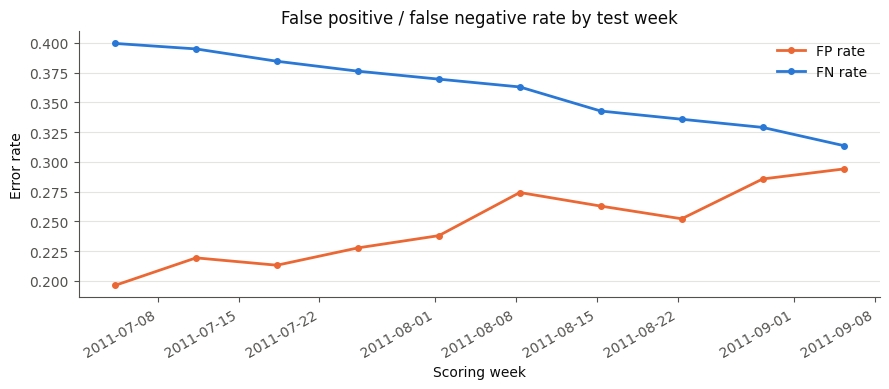

In [21]:
error_by_week = error_rate_by(test_df, "snapshot_date")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    error_by_week.index, error_by_week["fp_rate"], label="FP rate",
    color=COLOR_NEW, linewidth=2, marker="o", markersize=4,
)
ax.plot(
    error_by_week.index, error_by_week["fn_rate"], label="FN rate",
    color=COLOR_EXISTING, linewidth=2, marker="o", markersize=4,
)
ax.set_ylabel("Error rate")
ax.set_xlabel("Scoring week")
ax.set_title("False positive / false negative rate by test week")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

\textbf{Limitations.} Online Retail II contains no campaign
treatment/control information, so incremental revenue, causal
retention effect and true campaign ROI cannot be identified from
this data. Every business-impact figure in this chapter is a
scenario estimate under the stated assumptions ($e$, $m$,
$c_{\text{contact}}$, $c_{\text{inc}}$, $r$), not a measured
causal effect. The model identifies and prioritizes churn risk; the
retention campaign determines treatment; confirming real-world
incremental impact requires an actual campaign with a
treatment/control design.

## 7.11 Scoring Output

Score every customer-week of the test period plus the 13 unlabelable
weeks after it (2011-09-12 to 2011-12-05), which Section 5.4 notes
"can be scored but not evaluated" and which stand in for the
deployment batch, and save Section 8.3's customer risk output:
churn probability (raw and calibrated, Section 6.3), expected loss
= calibrated probability $\times$ `rar_v_orders` (Section 7.7), the
risk band (fixed cut-offs of Section 6.3, so band membership is
comparable across weeks for Section 8.6 monitoring) and `rank`, which
orders each week's customers by **expected loss** (1 = highest) --
the recommended targeting key. Outputs:
`data/results/churn_scores_h90.parquet` and
`models/churn_model_h90.joblib` (extended in place with the
expected-loss parameters).

In [22]:
scoring_df = modeling_dataset[
    (modeling_dataset["split"] == "test") | ~modeling_dataset["labelable"]
].copy()
scoring_df["split"] = scoring_df["split"].fillna("deployment")

X_score = scaler.transform(
    imputer.transform(prepare_features(scoring_df, FINAL_FEATURES))
)
scoring_logit = final_model.decision_function(X_score)
assert np.isfinite(scoring_logit).all()

scoring_df["churn_probability"] = final_model.predict_proba(X_score)[:, 1]
scoring_df["churn_probability_calibrated"] = expit(
    scoring_logit - CALIBRATION_OFFSET
)
scoring_df["expected_loss"] = (
    scoring_df["churn_probability_calibrated"]
    * scoring_df["value_v"]
    * expected_orders_in_h(scoring_df, H, MAX_ORDERS_IN_H)
)
assert np.allclose(
    scoring_df.loc[test_df.index, "churn_probability"],
    test_df["score_final_model"],
)
assert np.allclose(
    scoring_df.loc[test_df.index, "expected_loss"],
    test_df["score_expected_loss"],
)

scoring_df.groupby("split").agg(
    rows=("customer_id", "size"),
    weeks=("snapshot_date", "nunique"),
    first_week=("snapshot_date", "min"),
    last_week=("snapshot_date", "max"),
    mean_calibrated=("churn_probability_calibrated", "mean"),
    median_expected_loss=("expected_loss", "median"),
)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

,rows,weeks,first_week,last_week,mean_calibrated,median_expected_loss
split,,,,,,
deployment,36203,13,2011-09-12 07:45:00,2011-12-05 07:45:00,0.402676,140.899070
test,24252,10,2011-07-04 07:45:00,2011-09-05 07:45:00,0.417889,149.670467


In [23]:
scoring_df["risk_band"] = pd.cut(
    scoring_df["churn_probability_calibrated"], bins=risk_band_edges,
    right=False, labels=range(1, N_RISK_BANDS + 1),
).astype(int)
scoring_df["rank"] = (
    scoring_df.groupby("snapshot_date")["expected_loss"]
    .rank(ascending=False, method="first")
    .astype(int)
)

pd.DataFrame({
    "probability_from": risk_band_edges[:-1],
    "probability_below": risk_band_edges[1:],
}, index=pd.RangeIndex(1, N_RISK_BANDS + 1, name="risk_band")).round(3)

,probability_from,probability_below
risk_band,,
1,0.000,0.148
2,0.148,0.243
3,0.243,0.335
4,0.335,0.429
5,0.429,0.515
6,0.515,0.596
7,0.596,0.657
8,0.657,0.722
9,0.722,0.791


In [24]:
risk_band_summary = (
    scoring_df[scoring_df["split"] == "test"]
    .groupby("risk_band")
    .agg(
        customers=("customer_id", "size"),
        mean_calibrated=("churn_probability_calibrated", "mean"),
        churn_rate=("churn", "mean"),
    )
)
risk_band_summary.round(3)

,customers,mean_calibrated,churn_rate
risk_band,,,
1,3709,0.082,0.060
2,2998,0.195,0.194
3,2834,0.289,0.284
4,3087,0.383,0.417
5,2724,0.472,0.464
6,2405,0.555,0.521
7,1828,0.627,0.568
8,1927,0.688,0.626
9,1554,0.755,0.713


In [25]:
band_share = (
    scoring_df.groupby("split")["risk_band"]
    .value_counts(normalize=True)
    .unstack("split")
    .sort_index()
)
band_share.round(3)

split,deployment,test
risk_band,,
1,0.162,0.153
2,0.134,0.124
3,0.126,0.117
4,0.121,0.127
5,0.105,0.112
6,0.101,0.099
7,0.089,0.075
8,0.082,0.079
9,0.051,0.064


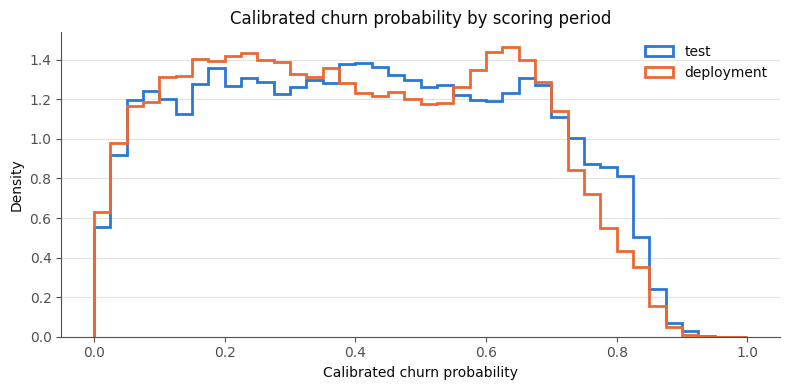

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 1.0001, 0.025)
for split, color in [("test", COLOR_EXISTING), ("deployment", COLOR_NEW)]:
    ax.hist(
        scoring_df.loc[
            scoring_df["split"] == split, "churn_probability_calibrated"
        ],
        bins=bins, density=True, histtype="step", linewidth=2,
        color=color, label=split,
    )
ax.set_xlabel("Calibrated churn probability")
ax.set_ylabel("Density")
ax.set_title("Calibrated churn probability by scoring period")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [27]:
assert (scoring_df["customer_id"] % 1 == 0).all()
scoring_output = (
    scoring_df.assign(
        customer_id=scoring_df["customer_id"].astype("int64"),
        model_version=MODEL_VERSION,
    )[[
        "customer_id", "snapshot_date", "segment", "split",
        "churn_probability", "churn_probability_calibrated",
        "expected_loss", "risk_band", "rank",
        "model_version", "churn",
    ]]
    .sort_values(["snapshot_date", "rank"])
    .reset_index(drop=True)
)

os.makedirs("../data/results", exist_ok=True)
out_path = f"../data/results/churn_scores_h{H}.parquet"
scoring_output.to_parquet(out_path, index=False)
print(f"Saved {len(scoring_output):,} rows to {out_path}")
scoring_output.head()

Saved 60,455 rows to ../data/results/churn_scores_h90.parquet


,customer_id,snapshot_date,segment,split,churn_probability,churn_probability_calibrated,expected_loss,risk_band,rank,model_version,churn
0,12432,2011-07-04 07:45:00,repeat,test,0.550819,0.486290,10483.575240,5,1,lr_extended_c0.01_weighted_cal_h90,1.0
1,15098,2011-07-04 07:45:00,repeat,test,0.306925,0.254763,6480.888289,3,2,lr_extended_c0.01_weighted_cal_h90,1.0
2,16766,2011-07-04 07:45:00,repeat,test,0.778165,0.730305,5438.139552,9,3,lr_extended_c0.01_weighted_cal_h90,1.0
3,12428,2011-07-04 07:45:00,repeat,test,0.399579,0.339381,3049.457974,4,4,lr_extended_c0.01_weighted_cal_h90,0.0
4,15700,2011-07-04 07:45:00,repeat,test,0.458002,0.394790,1787.773004,4,5,lr_extended_c0.01_weighted_cal_h90,1.0


In [28]:
model_artifact = {
    **base_artifact,
    "expected_orders_params": {
        "horizon_days": H, "max_orders": MAX_ORDERS_IN_H,
    },
}
assert model_artifact["model"] is final_model

joblib.dump(model_artifact, model_path)
print(f"Saved model with expected-loss parameters to {model_path}")

Saved model with expected-loss parameters to ../models/churn_model_h90.joblib


In [29]:
loaded_artifact = joblib.load(model_path)

X_check = scoring_df[loaded_artifact["features"]].copy()
for col in X_check.columns.intersection(loaded_artifact["log_features"]):
    X_check[col] = np.log1p(X_check[col])
X_check = loaded_artifact["scaler"].transform(
    loaded_artifact["imputer"].transform(X_check)
)
logit_check = loaded_artifact["model"].decision_function(X_check)
calibrated_check = expit(logit_check - loaded_artifact["calibration_offset"])
expected_loss_check = (
    calibrated_check * scoring_df["value_v"]
    * expected_orders_in_h(
        scoring_df, **loaded_artifact["expected_orders_params"]
    )
)
band_check = pd.cut(
    calibrated_check, bins=loaded_artifact["risk_band_edges"], right=False,
    labels=range(1, len(loaded_artifact["risk_band_edges"])),
).astype(int)

assert np.array_equal(band_check, scoring_df["risk_band"])
assert np.allclose(calibrated_check, scoring_df["churn_probability_calibrated"])
assert np.allclose(expected_loss_check, scoring_df["expected_loss"])
print(f"Round-trip check passed on {len(scoring_df):,} rows")

Round-trip check passed on 60,455 rows


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
